# Project 07 — Customer Support Hypothesis Testing & Operational Improvement

**Synthetic observational before/after evaluation**. This notebook will hold the audited source, descriptive KPIs, paired analysis, team ANOVA, guardrails, and management interpretations. Results will be calculated in Phases 2–4; the starter intentionally contains no findings.

## 1. Environment and source data

Load the one source CSV. Source grain: one ticket. Statistical pairing occurs at the agent level, **not** ticket-to-ticket.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

candidates = (Path("data/support_tickets.csv"), Path("../data/support_tickets.csv"))
source_path = next((p for p in candidates if p.exists()), None)
if source_path is None:
    raise FileNotFoundError("Open the repository folder and check data/support_tickets.csv")

tickets = pd.read_csv(source_path, parse_dates=["ticket_date"])
print(f"Loaded {len(tickets):,} simulated tickets, {tickets.agent_id.nunique()} agents")
print(f"Columns: {list(tickets.columns)}")
tickets.head()

Loaded 4,150 simulated tickets, 45 agents
Columns: ['ticket_id', 'ticket_date', 'intervention_period', 'agent_id', 'team', 'ticket_category', 'ticket_priority', 'ticket_complexity', 'response_time_minutes', 'resolution_time_minutes', 'csat_rating', 'sla_target_minutes', 'training_completed']


,ticket_id,ticket_date,intervention_period,agent_id,team,ticket_category,ticket_priority,ticket_complexity,response_time_minutes,resolution_time_minutes,csat_rating,sla_target_minutes,training_completed
0,TKT003427,2026-08-30,After,AGT030,Technical,Application Error,Medium,Moderate,12.58,229.82,3.0,20,True
1,TKT003390,2026-08-31,After,AGT029,Technical,Performance,High,Simple,10.17,174.89,4.0,10,True
2,TKT000678,2026-07-09,Before,AGT016,Technical,Login,Medium,Complex,34.20,205.77,3.0,20,False
3,TKT001516,2026-08-01,Before,AGT033,General,Order Status,Medium,Simple,9.00,51.40,NaN,20,False
4,TKT003763,2026-09-19,After,AGT037,General,Account Update,Low,Moderate,7.56,81.87,4.0,30,True


## 2. Consolidated audit, cleaning and validation

Phase 2: Run one full audit covering IDs, durations, categories, agent-team assignments, CSAT missingness, period consistency, case-mix drift, sample sufficiency, and outliers. Clean only actual problems; validate and freeze.

In [2]:
# ============================================================
# PROJECT 07 — PERMANENT DATE PARSING CORRECTION
# ============================================================

from pathlib import Path
import pandas as pd

# 1. Find the original source CSV

paths = [
    Path("data/support_tickets.csv"),
    Path("../data/support_tickets.csv")
]

source_path = next(
    (p for p in paths if p.is_file()),
    None
)

if source_path is None:
    raise FileNotFoundError("support_tickets.csv not found")

# 2. Reload the ORIGINAL CSV
# Do not automatically interpret dates during loading

tickets = pd.read_csv(
    source_path,
    dtype={"ticket_date": "string"}
)

# 3. Explicitly parse dates as YEAR-MONTH-DAY

tickets["ticket_date"] = pd.to_datetime(
    tickets["ticket_date"],
    format="%Y-%m-%d",
    errors="raise"
)

# 4. Verify known source records

expected_dates = {
    "TKT000678": "2026-07-09",
    "TKT001516": "2026-08-01",
    "TKT000764": "2026-08-11",
    "TKT003753": "2026-09-10"
}

for ticket_id, expected_date in expected_dates.items():

    actual_date = tickets.loc[
        tickets["ticket_id"] == ticket_id,
        "ticket_date"
    ].iloc[0].strftime("%Y-%m-%d")

    assert actual_date == expected_date, (
        f"{ticket_id}: Expected {expected_date}, "
        f"found {actual_date}"
    )

# 5. Confirm reporting dates

date_summary = tickets.groupby(
    "intervention_period"
)["ticket_date"].agg(["count", "min", "max"])

print("=== CORRECTED DATE SUMMARY ===")
display(date_summary)

print("\nTotal tickets:", len(tickets))
print("Unique agents:", tickets["agent_id"].nunique())

assert len(tickets) == 4150
assert tickets["agent_id"].nunique() == 45

print("\nDATE PARSING CORRECTED SUCCESSFULLY")

=== CORRECTED DATE SUMMARY ===


,count,min,max
intervention_period,,,
After,2100,2026-08-15,2026-09-28
Before,2050,2026-07-01,2026-08-14



Total tickets: 4150
Unique agents: 45

DATE PARSING CORRECTED SUCCESSFULLY


In [3]:
# ============================================================
# PROJECT 07 — PHASE 2.1
# CONSOLIDATED DATA QUALITY AUDIT
# ============================================================

from datetime import date
import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFY REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = {
    "ticket_id",
    "ticket_date",
    "intervention_period",
    "agent_id",
    "team",
    "ticket_category",
    "ticket_priority",
    "ticket_complexity",
    "response_time_minutes",
    "resolution_time_minutes",
    "csat_rating",
    "sla_target_minutes",
    "training_completed"
}

missing_columns = sorted(required_columns - set(tickets.columns))

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)


# ------------------------------------------------------------
# 2. PREPARE FIELDS FOR VALIDATION
# ------------------------------------------------------------

# Standardize text fields for checking.
# Original source data remains unchanged.

period = tickets["intervention_period"].astype("string").str.strip()
team = tickets["team"].astype("string").str.strip()
priority = tickets["ticket_priority"].astype("string").str.strip()
complexity = tickets["ticket_complexity"].astype("string").str.strip()

# Convert dates into proper datetime values.

dates = pd.to_datetime(
    tickets["ticket_date"],
    errors="coerce"
)

calendar_dates = dates.dt.date

# Convert numeric fields safely.

response = pd.to_numeric(
    tickets["response_time_minutes"],
    errors="coerce"
)

resolution = pd.to_numeric(
    tickets["resolution_time_minutes"],
    errors="coerce"
)

csat = pd.to_numeric(
    tickets["csat_rating"],
    errors="coerce"
)

sla = pd.to_numeric(
    tickets["sla_target_minutes"],
    errors="coerce"
)


# ------------------------------------------------------------
# 3. VALIDATE BEFORE/AFTER REPORTING DATES
# ------------------------------------------------------------

before = period.eq("Before")
after = period.eq("After")

# Compare calendar dates directly.
# Before: July 1 to August 14, 2026
# After: August 15 to September 28, 2026

valid_date = (
    dates.notna()
    &
    (
        (
            before
            & calendar_dates.between(
                date(2026, 7, 1),
                date(2026, 8, 14)
            )
        )
        |
        (
            after
            & calendar_dates.between(
                date(2026, 8, 15),
                date(2026, 9, 28)
            )
        )
    )
).fillna(False)


# ------------------------------------------------------------
# 4. CHECK AGENT COVERAGE ACROSS BOTH PERIODS
# ------------------------------------------------------------

agent_period_counts = (
    tickets.groupby(
        ["agent_id", "intervention_period"]
    )
    .size()
    .unstack(fill_value=0)
)

matched_agents = agent_period_counts.index[
    (agent_period_counts.get("Before", 0) >= 25)
    &
    (agent_period_counts.get("After", 0) >= 25)
]


# ------------------------------------------------------------
# 5. VALIDATE IDENTIFIERS
# ------------------------------------------------------------

id_present = (
    tickets["ticket_id"].notna()
    &
    tickets["ticket_id"]
    .astype("string")
    .str.strip()
    .ne("")
    .fillna(False)
)

required_identifiers = [
    "agent_id",
    "team",
    "ticket_category"
]

ids_populated = (
    tickets[required_identifiers]
    .notna()
    .all(axis=1)
)

for col in required_identifiers:
    ids_populated &= (
        tickets[col]
        .astype("string")
        .str.strip()
        .ne("")
        .fillna(False)
    )


# ------------------------------------------------------------
# 6. PREPARE SLA AND CSAT VALIDATION
# ------------------------------------------------------------

expected_sla = priority.map({
    "High": 10,
    "Medium": 20,
    "Low": 30
})

csat_valid = (
    tickets["csat_rating"].isna()
    |
    csat.isin([1, 2, 3, 4, 5])
).fillna(False)


# ------------------------------------------------------------
# 7. CONSOLIDATED 12 DATA QUALITY CHECKS
# ------------------------------------------------------------

checks = {

    "Unique and present ticket IDs":
        bool(
            id_present.all()
            and tickets["ticket_id"].is_unique
        ),

    "No duplicate records":
        bool(
            not tickets.duplicated().any()
        ),

    "Required identifiers populated":
        bool(
            ids_populated.all()
        ),

    "Valid intervention periods":
        bool(
            period.isin(["Before", "After"]).all()
            and set(period.dropna()) == {"Before", "After"}
        ),

    "Valid teams, priorities and complexity":
        bool(
            team.isin(
                ["Billing", "General", "Technical"]
            ).all()
            and priority.isin(
                ["Low", "Medium", "High"]
            ).all()
            and complexity.isin(
                ["Simple", "Moderate", "Complex"]
            ).all()
        ),

    "Valid response and resolution times":
        bool(
            response.gt(0).all()
            and resolution.ge(response).all()
        ),

    "Valid CSAT ratings":
        bool(
            csat_valid.all()
        ),

    "Correct SLA targets":
        bool(
            sla.eq(expected_sla).all()
        ),

    "Consistent agent-team assignments":
        bool(
            tickets.groupby("agent_id")["team"]
            .nunique()
            .eq(1)
            .all()
        ),

    "Correct training flags":
        bool(
            tickets["training_completed"]
            .eq(after)
            .all()
        ),

    "Correct reporting dates":
        bool(
            valid_date.all()
        ),

    "Sufficient tickets per agent":
        bool(
            len(matched_agents) == tickets["agent_id"].nunique()
            and len(matched_agents) > 0
        )
}


# ------------------------------------------------------------
# 8. DISPLAY CONSOLIDATED AUDIT RESULTS
# ------------------------------------------------------------

audit = pd.DataFrame({
    "Check": list(checks),
    "Status": [
        "PASS" if passed else "FAIL"
        for passed in checks.values()
    ]
})

print("=== 1. CONSOLIDATED DATA QUALITY AUDIT ===")

display(audit)

print(
    "Checks passed:",
    (audit["Status"] == "PASS").sum(),
    "/12"
)


# ------------------------------------------------------------
# 9. DATASET COVERAGE
# ------------------------------------------------------------

coverage = pd.DataFrame({
    "Metric": [
        "Total Tickets",
        "Total Agents",
        "Matched Agents",
        "Distinct Teams",
        "Duplicate Rows"
    ],

    "Value": [
        len(tickets),
        tickets["agent_id"].nunique(),
        len(matched_agents),
        tickets["team"].nunique(),
        int(tickets.duplicated().sum())
    ]
})

print("\n=== 2. DATASET COVERAGE ===")

display(coverage)


# ------------------------------------------------------------
# 10. REPORTING DATE DIAGNOSTICS
# ------------------------------------------------------------

date_overview = pd.DataFrame({
    "Period": period,
    "Date": dates
})

date_summary = (
    date_overview.groupby("Period")["Date"]
    .agg(["count", "min", "max"])
    .reset_index()
)

print("\n=== 3. REPORTING DATE VALIDATION ===")

display(date_summary)

print(
    "Invalid reporting dates:",
    int((~valid_date).sum())
)

# Show problematic dates only when they exist.

if not valid_date.all():

    print("\nInvalid date records:")

    display(
        tickets.loc[
            ~valid_date,
            [
                "ticket_id",
                "intervention_period",
                "ticket_date"
            ]
        ].head(20)
    )


# ------------------------------------------------------------
# 11. MISSING VALUE SUMMARY
# ------------------------------------------------------------

missing = tickets.isna().sum()

print("\n=== 4. MISSING VALUES ===")

display(
    missing[missing > 0]
    .rename("Missing Records")
    .to_frame()
)


# ------------------------------------------------------------
# 12. TICKET MIX AND CUSTOMER SATISFACTION COVERAGE
# ------------------------------------------------------------

case_mix = pd.DataFrame({

    "Period": ["Before", "After"],

    "Tickets": [
        int(before.sum()),
        int(after.sum())
    ],

    "High Priority (%)": [
        priority[before].eq("High").mean() * 100,
        priority[after].eq("High").mean() * 100
    ],

    "Complex (%)": [
        complexity[before].eq("Complex").mean() * 100,
        complexity[after].eq("Complex").mean() * 100
    ],

    "CSAT Response (%)": [
        csat[before].notna().mean() * 100,
        csat[after].notna().mean() * 100
    ]

})

print("\n=== 5. TICKET MIX AND CSAT COVERAGE ===")

display(case_mix.round(2))


# ------------------------------------------------------------
# 13. RESPONSE-TIME OUTLIER REVIEW
# ------------------------------------------------------------

print("\n=== 6. RESPONSE TIME OUTLIER REVIEW ===")

print(
    "99th percentile (minutes):",
    round(float(response.quantile(0.99)), 2)
)

print(
    "Maximum (minutes):",
    round(float(response.max()), 2)
)


# ------------------------------------------------------------
# 14. FINAL VALIDATION AND DATASET FREEZE
# ------------------------------------------------------------

failed_checks = audit[
    audit["Status"] == "FAIL"
]

if not failed_checks.empty:

    print("\n=== FAILED VALIDATION CHECKS ===")

    display(failed_checks)

    raise ValueError(
        "Audit failed. Review failed checks before analysis."
    )

# Create validated working dataset only after all checks pass.

clean = tickets.copy()

print("\n" + "=" * 50)
print("AUDIT PASSED — DATASET VALIDATED")
print("12/12 DATA QUALITY CHECKS PASSED")
print("Validated dataset 'clean' is ready")
print("=" * 50)

=== 1. CONSOLIDATED DATA QUALITY AUDIT ===


,Check,Status
0,Unique and present ticket IDs,PASS
1,No duplicate records,PASS
2,Required identifiers populated,PASS
3,Valid intervention periods,PASS
4,"Valid teams, priorities and complexity",PASS
5,Valid response and resolution times,PASS
6,Valid CSAT ratings,PASS
7,Correct SLA targets,PASS
8,Consistent agent-team assignments,PASS
9,Correct training flags,PASS


Checks passed: 12 /12

=== 2. DATASET COVERAGE ===


,Metric,Value
0,Total Tickets,4150
1,Total Agents,45
2,Matched Agents,45
3,Distinct Teams,3
4,Duplicate Rows,0



=== 3. REPORTING DATE VALIDATION ===


,Period,count,min,max
0,After,2100,2026-08-15,2026-09-28
1,Before,2050,2026-07-01,2026-08-14


Invalid reporting dates: 0

=== 4. MISSING VALUES ===


,Missing Records
csat_rating,933



=== 5. TICKET MIX AND CSAT COVERAGE ===


,Period,Tickets,High Priority (%),Complex (%),CSAT Response (%)
0,Before,2050,21.71,20.88,78.34
1,After,2100,28.05,27.76,76.71



=== 6. RESPONSE TIME OUTLIER REVIEW ===
99th percentile (minutes): 46.12
Maximum (minutes): 94.25

AUDIT PASSED — DATASET VALIDATED
12/12 DATA QUALITY CHECKS PASSED
Validated dataset 'clean' is ready


## 3. Descriptive operational KPIs

Phase 2: Compute ticket-weighted response-time summaries, median, volume, SLA compliance, resolution-time summaries, CSAT mean and response rate, and team/priority/complexity breakdowns.

In [4]:
# PHASE 2.2 — OPERATIONAL KPI ANALYSIS

import pandas as pd
import numpy as np

clean = tickets.copy()

# Create operational KPI fields
clean["csat_rating"] = pd.to_numeric(
    clean["csat_rating"], errors="coerce"
)

clean["sla_met"] = (
    clean["response_time_minutes"]
    <= clean["sla_target_minutes"]
)

# 1. BEFORE/AFTER OPERATIONAL SCORECARD

overview = (
    clean.groupby("intervention_period")
    .agg(
        tickets=("ticket_id", "size"),
        agents=("agent_id", "nunique"),
        mean_response_min=("response_time_minutes", "mean"),
        median_response_min=("response_time_minutes", "median"),
        mean_resolution_min=("resolution_time_minutes", "mean"),
        sla_compliance_pct=(
            "sla_met", lambda x: x.mean() * 100
        ),
        mean_csat=("csat_rating", "mean"),
        csat_response_pct=(
            "csat_rating", lambda x: x.notna().mean() * 100
        ),
        satisfied_pct=(
            "csat_rating",
            lambda x: x.ge(4).sum() / x.notna().sum() * 100
        )
    )
    .reindex(["Before", "After"])
)

print("=== 1. BEFORE/AFTER KPI SCORECARD ===")
print(overview.T.round(2).to_string())

# 2. RESPONSE-TIME IMPROVEMENT

before = overview.loc["Before", "mean_response_min"]
after = overview.loc["After", "mean_response_min"]

absolute_reduction = before - after
relative_reduction = absolute_reduction / before * 100

print("\n=== 2. RESPONSE-TIME CHANGE ===")
print(f"Before: {before:.2f} minutes")
print(f"After: {after:.2f} minutes")
print(f"Absolute reduction: {absolute_reduction:.2f} minutes")
print(f"Relative reduction: {relative_reduction:.2f}%")

# 3. TEAM PERFORMANCE

team_metrics = (
    clean.groupby(["team", "intervention_period"])
    .agg(
        tickets=("ticket_id", "size"),
        mean_response=("response_time_minutes", "mean"),
        sla_pct=("sla_met", lambda x: x.mean() * 100),
        csat=("csat_rating", "mean")
    )
    .round(2)
)

print("\n=== 3. TEAM PERFORMANCE ===")
print(team_metrics.to_string())

# 4. PRIORITY AND COMPLEXITY MIX

print("\n=== 4. TICKET PRIORITY MIX (%) ===")
print(
    pd.crosstab(
        clean["ticket_priority"],
        clean["intervention_period"],
        normalize="columns"
    ).mul(100).round(2).to_string()
)

print("\n=== 5. TICKET COMPLEXITY MIX (%) ===")
print(
    pd.crosstab(
        clean["ticket_complexity"],
        clean["intervention_period"],
        normalize="columns"
    ).mul(100).round(2).to_string()
)

# 5. TICKET VOLUME CHANGE

before_volume = overview.loc["Before", "tickets"]
after_volume = overview.loc["After", "tickets"]

volume_change = (
    (after_volume - before_volume) / before_volume * 100
)

print("\n=== 6. TICKET VOLUME ===")
print(f"Before: {before_volume:.0f}")
print(f"After: {after_volume:.0f}")
print(f"Volume change: {volume_change:+.2f}%")

print("\nPHASE 2.2 — OPERATIONAL KPIs CALCULATED")

=== 1. BEFORE/AFTER KPI SCORECARD ===
intervention_period   Before    After
tickets              2050.00  2100.00
agents                 45.00    45.00
mean_response_min      15.06    14.22
median_response_min    12.65    11.94
mean_resolution_min   124.85   129.05
sla_compliance_pct     75.02    76.14
mean_csat               3.97     4.04
csat_response_pct      78.34    76.71
satisfied_pct          70.30    75.42

=== 2. RESPONSE-TIME CHANGE ===
Before: 15.06 minutes
After: 14.22 minutes
Absolute reduction: 0.84 minutes
Relative reduction: 5.57%

=== 3. TEAM PERFORMANCE ===
                               tickets  mean_response  sla_pct  csat
team      intervention_period                                       
Billing   After                    740          13.09    80.95  4.11
          Before                   665          14.83    75.04  3.99
General   After                    676          11.82    82.40  4.06
          Before                   665          12.57    85.41  4.01
Tech

## 4. Matched agent-level analysis table

Phase 2: Construct one before and one after mean response time per matched agent. Track ticket counts in both periods. Define paired difference as **after − before** and team improvement as **before − after**.

In [5]:
# PHASE 2.4 — AGENT-LEVEL BEFORE/AFTER PAIRING

import pandas as pd
import numpy as np
from IPython.display import display

# STEP 1: Calculate metrics per agent and period

agent_summary = (
    clean.groupby(
        ["agent_id", "team", "intervention_period"]
    )
    .agg(
        avg_response=("response_time_minutes", "mean"),
        tickets=("ticket_id", "size")
    )
    .reset_index()
)

# STEP 2: Convert Before and After into separate columns

agent_pairs = agent_summary.pivot(
    index=["agent_id", "team"],
    columns="intervention_period",
    values=["avg_response", "tickets"]
)

# STEP 3: Flatten multi-level column names

agent_pairs.columns = [
    f"{metric}_{period.lower()}"
    for metric, period in agent_pairs.columns
]

agent_pairs = agent_pairs.reset_index()

# STEP 4: Validate matched agents

assert agent_pairs[
    ["avg_response_before", "avg_response_after"]
].notna().all().all(), "Some agents lack a reporting period"

assert (
    (agent_pairs["tickets_before"] >= 25)
    &
    (agent_pairs["tickets_after"] >= 25)
).all(), "Insufficient ticket coverage"

assert len(agent_pairs) == 45, "Unexpected agent count"

# STEP 5: Calculate individual improvements

agent_pairs["improvement_min"] = (
    agent_pairs["avg_response_before"]
    - agent_pairs["avg_response_after"]
)

agent_pairs["improvement_pct"] = (
    agent_pairs["improvement_min"]
    / agent_pairs["avg_response_before"]
    * 100
)

# STEP 6: Display paired agent table

print("=== MATCHED AGENT-LEVEL DATASET ===")
print("Matched agents:", len(agent_pairs))

display(agent_pairs.head(10).round(2))

# STEP 7: Calculate agent-weighted averages

agent_before = agent_pairs["avg_response_before"].mean()
agent_after = agent_pairs["avg_response_after"].mean()
mean_improvement = agent_pairs["improvement_min"].mean()

print("\n=== AGENT-WEIGHTED COMPARISON ===")
print(f"Before: {agent_before:.2f} minutes")
print(f"After: {agent_after:.2f} minutes")
print(f"Mean improvement: {mean_improvement:.2f} minutes")

# STEP 8: Count agents who improved or deteriorated

improved = (agent_pairs["improvement_min"] > 0).sum()
deteriorated = (agent_pairs["improvement_min"] < 0).sum()
unchanged = (agent_pairs["improvement_min"] == 0).sum()

print("\n=== AGENT IMPROVEMENT COUNTS ===")
print("Improved:", improved)
print("Deteriorated:", deteriorated)
print("Unchanged:", unchanged)

assert improved + deteriorated + unchanged == 45

# STEP 9: Summarize team-level improvements

team_improvement = (
    agent_pairs.groupby("team")
    .agg(
        agents=("agent_id", "size"),
        before_avg=("avg_response_before", "mean"),
        after_avg=("avg_response_after", "mean"),
        mean_improvement=("improvement_min", "mean"),
        improved_agents=(
            "improvement_min",
            lambda x: (x > 0).sum()
        )
    )
    .round(2)
)

print("\n=== TEAM-LEVEL AGENT IMPROVEMENTS ===")
display(team_improvement)

print("\nPHASE 2.4 — AGENT PAIRING COMPLETE")

=== MATCHED AGENT-LEVEL DATASET ===
Matched agents: 45


,agent_id,team,avg_response_after,avg_response_before,tickets_after,tickets_before,improvement_min,improvement_pct
0,AGT001,Billing,11.89,12.93,49.0,40.0,1.03,7.99
1,AGT002,Billing,17.84,21.71,54.0,42.0,3.87,17.83
2,AGT003,Billing,8.53,12.83,50.0,49.0,4.30,33.51
3,AGT004,Billing,12.60,11.19,41.0,49.0,-1.41,-12.58
4,AGT005,Billing,9.18,13.56,46.0,50.0,4.38,32.28
5,AGT006,Billing,16.60,17.31,54.0,45.0,0.71,4.10
6,AGT007,Billing,14.57,16.70,49.0,46.0,2.13,12.76
7,AGT008,Billing,14.56,14.75,47.0,39.0,0.19,1.31
8,AGT009,Billing,12.82,16.62,58.0,43.0,3.80,22.84
9,AGT010,Billing,14.15,20.53,53.0,39.0,6.38,31.08



=== AGENT-WEIGHTED COMPARISON ===
Before: 15.01 minutes
After: 14.20 minutes
Mean improvement: 0.82 minutes

=== AGENT IMPROVEMENT COUNTS ===
Improved: 27
Deteriorated: 18
Unchanged: 0

=== TEAM-LEVEL AGENT IMPROVEMENTS ===


,agents,before_avg,after_avg,mean_improvement,improved_agents
team,,,,,
Billing,15,14.92,13.06,1.86,11
General,15,12.63,11.89,0.73,10
Technical,15,17.49,17.63,-0.14,6



PHASE 2.4 — AGENT PAIRING COMPLETE


## 5. Paired t-test and 95% confidence interval

Phase 3: Explain assumptions, calculate the mean difference, standard deviation, t-statistic, degrees of freedom, two-sided p-value, confidence interval, and effect size. Check against SciPy outputs.

=== 1. PAIRED DIFFERENCE SUMMARY ===


,Metric,Value
0,Paired Agents,45.000
1,Mean Improvement (min),0.819
2,Median Improvement (min),0.710
3,Standard Deviation,2.928
4,Minimum Improvement,-10.242
5,Maximum Improvement,6.755
6,Q1,-0.861
7,Q3,2.732
8,IQR,3.593



=== 2. POTENTIAL OUTLIERS ===
Outlier count: 1


,agent_id,team,improvement_min
27,AGT028,Technical,-10.24



=== 3. NORMALITY DIAGNOSTIC ===
Shapiro-Wilk W: 0.9236
P-value: 0.0056
Evidence of departure from normality.


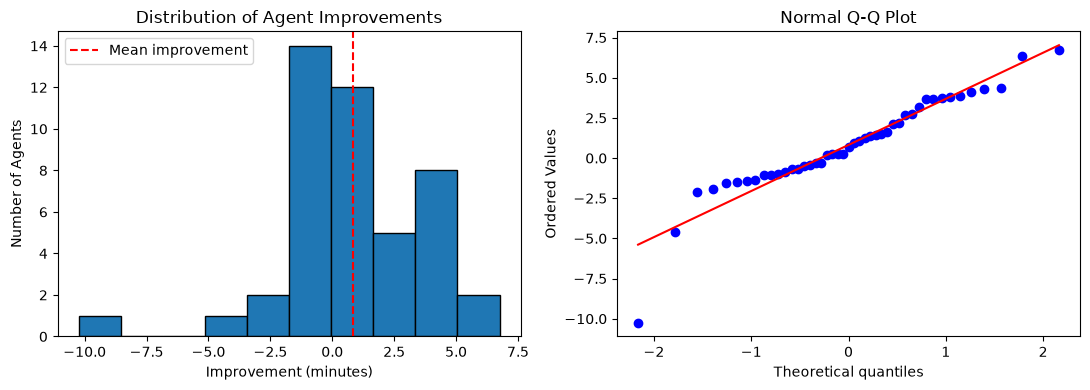


PHASE 2.5 — ASSUMPTION CHECKS COMPLETE


In [6]:
# PHASE 2.5 — PAIRED DIFFERENCE VALIDATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# 1. Collect the 45 agent-level differences

differences = agent_pairs["improvement_min"].astype(float)

assert len(differences) == 45
assert np.isfinite(differences).all()

# 2. Descriptive statistics

n = len(differences)
mean_diff = differences.mean()
std_diff = differences.std(ddof=1)
median_diff = differences.median()

q1 = differences.quantile(0.25)
q3 = differences.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

summary = pd.DataFrame({
    "Metric": [
        "Paired Agents",
        "Mean Improvement (min)",
        "Median Improvement (min)",
        "Standard Deviation",
        "Minimum Improvement",
        "Maximum Improvement",
        "Q1",
        "Q3",
        "IQR"
    ],
    "Value": [
        n,
        mean_diff,
        median_diff,
        std_diff,
        differences.min(),
        differences.max(),
        q1,
        q3,
        iqr
    ]
})

print("=== 1. PAIRED DIFFERENCE SUMMARY ===")
display(summary.round(3))

# 3. Identify potential extreme observations

outliers = agent_pairs.loc[
    (differences < lower_bound) |
    (differences > upper_bound),
    ["agent_id", "team", "improvement_min"]
].copy()

print("\n=== 2. POTENTIAL OUTLIERS ===")
print("Outlier count:", len(outliers))

display(outliers.round(2))

# 4. Shapiro-Wilk normality diagnostic

shapiro_stat, shapiro_p = stats.shapiro(differences)

print("\n=== 3. NORMALITY DIAGNOSTIC ===")
print(f"Shapiro-Wilk W: {shapiro_stat:.4f}")
print(f"P-value: {shapiro_p:.4f}")

if shapiro_p < 0.05:
    print("Evidence of departure from normality.")
else:
    print("No significant departure from normality detected.")

# 5. Visual diagnostic

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(
    differences,
    bins=10,
    edgecolor="black"
)
axes[0].axvline(
    mean_diff,
    color="red",
    linestyle="--",
    label="Mean improvement"
)

axes[0].set_title("Distribution of Agent Improvements")
axes[0].set_xlabel("Improvement (minutes)")
axes[0].set_ylabel("Number of Agents")
axes[0].legend()

stats.probplot(
    differences,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

print("\nPHASE 2.5 — ASSUMPTION CHECKS COMPLETE")

In [7]:
# PHASE 3.1 — PAIRED T-TEST AND SENSITIVITY ANALYSIS

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

# 1. Use all 45 matched agents for primary analysis

before = agent_pairs["avg_response_before"].to_numpy()
after = agent_pairs["avg_response_after"].to_numpy()

d = before - after

n = len(d)
mean_d = np.mean(d)
sd_d = np.std(d, ddof=1)
se_d = sd_d / np.sqrt(n)

df = n - 1

# 2. Manual paired t-statistic

t_manual = mean_d / se_d

# 3. SciPy paired t-test

result = stats.ttest_rel(
    before,
    after,
    alternative="two-sided"
)

# Verify manual and library results
assert np.isclose(t_manual, result.statistic)

# 4. Calculate 95% confidence interval

t_critical = stats.t.ppf(0.975, df)

ci_lower = mean_d - t_critical * se_d
ci_upper = mean_d + t_critical * se_d

# 5. Paired Cohen's d effect size

cohens_dz = mean_d / sd_d

primary = pd.DataFrame({
    "Metric": [
        "Paired Agents",
        "Mean Improvement (min)",
        "Standard Deviation",
        "Standard Error",
        "Manual t-statistic",
        "SciPy t-statistic",
        "Degrees of Freedom",
        "Two-Sided P-value",
        "95% CI Lower",
        "95% CI Upper",
        "Cohen's dz"
    ],
    "Value": [
        n,
        mean_d,
        sd_d,
        se_d,
        t_manual,
        result.statistic,
        df,
        result.pvalue,
        ci_lower,
        ci_upper,
        cohens_dz
    ]
})

print("=== PRIMARY PAIRED T-TEST: ALL AGENTS ===")
display(primary.round(4))

# 6. Sensitivity analysis:
# Temporarily exclude the identified outlier.
# DO NOT modify agent_pairs or the original dataset.

sensitivity = agent_pairs[
    agent_pairs["agent_id"] != "AGT028"
].copy()

d_sensitivity = sensitivity["improvement_min"].to_numpy()

n_s = len(d_sensitivity)
mean_s = np.mean(d_sensitivity)
sd_s = np.std(d_sensitivity, ddof=1)
se_s = sd_s / np.sqrt(n_s)

result_s = stats.ttest_1samp(
    d_sensitivity,
    popmean=0,
    alternative="two-sided"
)

t_critical_s = stats.t.ppf(0.975, n_s - 1)

ci_lower_s = mean_s - t_critical_s * se_s
ci_upper_s = mean_s + t_critical_s * se_s

comparison = pd.DataFrame({
    "Metric": [
        "Agents",
        "Mean Improvement",
        "t-statistic",
        "P-value",
        "95% CI Lower",
        "95% CI Upper"
    ],
    "All 45 Agents": [
        n,
        mean_d,
        result.statistic,
        result.pvalue,
        ci_lower,
        ci_upper
    ],
    "Without AGT028": [
        n_s,
        mean_s,
        result_s.statistic,
        result_s.pvalue,
        ci_lower_s,
        ci_upper_s
    ]
})

print("\n=== SENSITIVITY COMPARISON ===")
display(comparison.round(4))

print("\n=== PRIMARY TEST DECISION ===")

if result.pvalue < 0.05:
    print("Reject H0 at alpha = 0.05.")
else:
    print("Do not reject H0 at alpha = 0.05.")

print(
    "\nSensitivity results are diagnostic, "
    "not a replacement for the primary test."
)

print("\nPHASE 3.1 — COMPLETE")

=== PRIMARY PAIRED T-TEST: ALL AGENTS ===


,Metric,Value
0,Paired Agents,45.0000
1,Mean Improvement (min),0.8186
2,Standard Deviation,2.9277
3,Standard Error,0.4364
4,Manual t-statistic,1.8757
5,SciPy t-statistic,1.8757
6,Degrees of Freedom,44.0000
7,Two-Sided P-value,0.0673
8,95% CI Lower,-0.0610
9,95% CI Upper,1.6982



=== SENSITIVITY COMPARISON ===


,Metric,All 45 Agents,Without AGT028
0,Agents,45.0000,44.0000
1,Mean Improvement,0.8186,1.0700
2,t-statistic,1.8757,2.9317
3,P-value,0.0673,0.0054
4,95% CI Lower,-0.0610,0.3340
5,95% CI Upper,1.6982,1.8060



=== PRIMARY TEST DECISION ===
Do not reject H0 at alpha = 0.05.

Sensitivity results are diagnostic, not a replacement for the primary test.

PHASE 3.1 — COMPLETE


## 6. ANOVA: team differences in agent improvement

Phase 3: Compare agent-level improvements among Billing, Technical, and General. Check assumptions and assess post-hoc comparisons only when justified.

In [8]:
# PHASE 3.2 — TEAM-LEVEL ANOVA

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from IPython.display import display

# 1. Create three independent groups of agent improvements

groups = {
    team: group["improvement_min"].to_numpy(dtype=float)
    for team, group in agent_pairs.groupby("team")
}

assert set(groups) == {"Billing", "General", "Technical"}
assert sum(len(x) for x in groups.values()) == 45

# 2. Team-level descriptive summary

team_summary = (
    agent_pairs.groupby("team")["improvement_min"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .round(4)
)

print("=== 1. TEAM IMPROVEMENT SUMMARY ===")
display(team_summary)

# 3. Normality diagnostics for each team

normality_results = []

for team, values in groups.items():
    w, p = stats.shapiro(values)

    normality_results.append({
        "Team": team,
        "Shapiro W": w,
        "P-value": p
    })

print("\n=== 2. TEAM NORMALITY DIAGNOSTICS ===")
display(pd.DataFrame(normality_results).round(4))

# 4. Levene test for equality of variances
# Median-centered version is more robust to outliers.

levene_stat, levene_p = stats.levene(
    *groups.values(),
    center="median"
)

print("\n=== 3. EQUALITY OF VARIANCES ===")
print(f"Levene statistic: {levene_stat:.4f}")
print(f"Levene p-value: {levene_p:.4f}")

# 5. Classical One-Way ANOVA

f_scipy, p_anova = stats.f_oneway(
    *groups.values()
)

# 6. Manual verification of F-statistic

all_values = np.concatenate(list(groups.values()))
grand_mean = all_values.mean()

ss_between = sum(
    len(values) * (values.mean() - grand_mean)**2
    for values in groups.values()
)

ss_within = sum(
    np.sum((values - values.mean())**2)
    for values in groups.values()
)

k = len(groups)
n = len(all_values)

df_between = k - 1
df_within = n - k

ms_between = ss_between / df_between
ms_within = ss_within / df_within

f_manual = ms_between / ms_within

assert np.isclose(f_manual, f_scipy)

# 7. Eta-squared effect size

eta_squared = ss_between / (ss_between + ss_within)

anova_results = pd.DataFrame({
    "Metric": [
        "Number of Teams",
        "Number of Agents",
        "SS Between",
        "SS Within",
        "DF Between",
        "DF Within",
        "MS Between",
        "MS Within",
        "Manual F-statistic",
        "SciPy F-statistic",
        "ANOVA P-value",
        "Eta-squared"
    ],
    "Value": [
        k, n,
        ss_between, ss_within,
        df_between, df_within,
        ms_between, ms_within,
        f_manual, f_scipy,
        p_anova, eta_squared
    ]
})

print("\n=== 4. CLASSICAL ONE-WAY ANOVA ===")
display(anova_results.round(4))

# 8. Welch ANOVA as a variance-robust comparison

welch = anova_oneway(
    list(groups.values()),
    use_var="unequal"
)

print("\n=== 5. WELCH ANOVA COMPARISON ===")
print(f"F-statistic: {welch.statistic:.4f}")
print(f"P-value: {welch.pvalue:.4f}")
print(f"Degrees of freedom: {welch.df}")

print("\nPHASE 3.2 — ANOVA CALCULATED")

=== 1. TEAM IMPROVEMENT SUMMARY ===


,count,mean,std,median,min,max
team,,,,,,
Billing,15,1.8606,2.4625,1.5236,-2.1416,6.3813
General,15,0.7348,2.3297,1.2471,-4.6293,4.1066
Technical,15,-0.1396,3.6459,-0.4785,-10.2423,6.7552



=== 2. TEAM NORMALITY DIAGNOSTICS ===


,Team,Shapiro W,P-value
0,Billing,0.9603,0.6982
1,General,0.9547,0.6019
2,Technical,0.8433,0.0140



=== 3. EQUALITY OF VARIANCES ===
Levene statistic: 0.1419
Levene p-value: 0.8681

=== 4. CLASSICAL ONE-WAY ANOVA ===


,Metric,Value
0,Number of Teams,3.0000
1,Number of Agents,45.0000
2,SS Between,30.1649
3,SS Within,346.9801
4,DF Between,2.0000
5,DF Within,42.0000
6,MS Between,15.0824
7,MS Within,8.2614
8,Manual F-statistic,1.8256
9,SciPy F-statistic,1.8256



=== 5. WELCH ANOVA COMPARISON ===
F-statistic: 1.7034
P-value: 0.2009
Degrees of freedom: (2.0, np.float64(27.232630041980446))

PHASE 3.2 — ANOVA CALCULATED


In [9]:
# ============================================================
# PHASE 3.3 — AGT028 INVESTIGATION & ANOVA SENSITIVITY
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from IPython.display import display

# ------------------------------------------------------------
# 1. EXTRACT AGT028 TICKETS
# ------------------------------------------------------------

agent_028 = clean.loc[
    clean["agent_id"] == "AGT028"
].copy()

assert not agent_028.empty, "AGT028 not found"

assert agent_028["team"].eq("Technical").all()

# Create temporary analytical fields

agent_028["sla_met"] = (
    agent_028["response_time_minutes"]
    <= agent_028["sla_target_minutes"]
)

agent_028["is_high"] = (
    agent_028["ticket_priority"] == "High"
)

agent_028["is_complex"] = (
    agent_028["ticket_complexity"] == "Complex"
)

# ------------------------------------------------------------
# 2. BEFORE/AFTER AGENT PERFORMANCE
# ------------------------------------------------------------

agent_performance = (
    agent_028.groupby("intervention_period")
    .agg(
        tickets=("ticket_id", "size"),

        mean_response=(
            "response_time_minutes", "mean"
        ),

        median_response=(
            "response_time_minutes", "median"
        ),

        p90_response=(
            "response_time_minutes",
            lambda x: x.quantile(0.90)
        ),

        mean_resolution=(
            "resolution_time_minutes", "mean"
        ),

        sla_pct=(
            "sla_met",
            lambda x: x.mean() * 100
        ),

        high_priority_pct=(
            "is_high",
            lambda x: x.mean() * 100
        ),

        complex_pct=(
            "is_complex",
            lambda x: x.mean() * 100
        ),

        mean_csat=("csat_rating", "mean")
    )
    .reindex(["Before", "After"])
)

print("=== 1. AGT028 PERFORMANCE COMPARISON ===")
display(agent_performance.T.round(2))

# ------------------------------------------------------------
# 3. INVESTIGATE TICKET PRIORITY MIX
# ------------------------------------------------------------

priority_mix = pd.crosstab(
    agent_028["intervention_period"],
    agent_028["ticket_priority"],
    normalize="index"
).mul(100)

print("\n=== 2. AGT028 TICKET PRIORITY MIX (%) ===")
display(priority_mix.round(2))

# ------------------------------------------------------------
# 4. INVESTIGATE TICKET COMPLEXITY MIX
# ------------------------------------------------------------

complexity_mix = pd.crosstab(
    agent_028["intervention_period"],
    agent_028["ticket_complexity"],
    normalize="index"
).mul(100)

print("\n=== 3. AGT028 TICKET COMPLEXITY MIX (%) ===")
display(complexity_mix.round(2))

# ------------------------------------------------------------
# 5. TECHNICAL TEAM WITHOUT AGT028
# ------------------------------------------------------------

technical_all = agent_pairs.loc[
    agent_pairs["team"] == "Technical"
]

technical_without = technical_all.loc[
    technical_all["agent_id"] != "AGT028"
]

technical_comparison = pd.DataFrame({
    "Metric": [
        "Agents",
        "Mean Before (min)",
        "Mean After (min)",
        "Mean Improvement (min)",
        "Improved Agents"
    ],

    "All 15 Technical Agents": [
        len(technical_all),
        technical_all["avg_response_before"].mean(),
        technical_all["avg_response_after"].mean(),
        technical_all["improvement_min"].mean(),
        technical_all["improvement_min"].gt(0).sum()
    ],

    "Without AGT028": [
        len(technical_without),
        technical_without["avg_response_before"].mean(),
        technical_without["avg_response_after"].mean(),
        technical_without["improvement_min"].mean(),
        technical_without["improvement_min"].gt(0).sum()
    ]
})

print("\n=== 4. TECHNICAL TEAM SENSITIVITY ===")
display(technical_comparison.round(3))

# ------------------------------------------------------------
# 6. ANOVA SENSITIVITY FUNCTION
# ------------------------------------------------------------

def calculate_team_anova(data):

    grouped = {
        name: group["improvement_min"].to_numpy()
        for name, group in data.groupby("team")
    }

    assert set(grouped) == {
        "Billing", "General", "Technical"
    }

    classical_f, classical_p = stats.f_oneway(
        *grouped.values()
    )

    welch = anova_oneway(
        list(grouped.values()),
        use_var="unequal"
    )

    technical_shapiro = stats.shapiro(
        grouped["Technical"]
    )

    return {
        "Agents": len(data),

        "Billing Mean": grouped["Billing"].mean(),
        "General Mean": grouped["General"].mean(),
        "Technical Mean": grouped["Technical"].mean(),

        "Classical F": classical_f,
        "Classical P": classical_p,

        "Welch F": welch.statistic,
        "Welch P": welch.pvalue,

        "Technical Shapiro P": technical_shapiro.pvalue
    }

# ------------------------------------------------------------
# 7. COMPARE PRIMARY VS SENSITIVITY ANOVA
# ------------------------------------------------------------

without_028 = agent_pairs.loc[
    agent_pairs["agent_id"] != "AGT028"
].copy()

anova_comparison = pd.DataFrame(
    [
        calculate_team_anova(agent_pairs),
        calculate_team_anova(without_028)
    ],
    index=[
        "All 45 Agents — Primary",
        "44 Agents — Sensitivity"
    ]
)

print("\n=== 5. ANOVA SENSITIVITY COMPARISON ===")
display(anova_comparison.T.round(4))

# ------------------------------------------------------------
# 8. AUTOMATED STATISTICAL DECISIONS
# ------------------------------------------------------------

print("\n=== 6. ANOVA DECISION COMPARISON ===")

for label, row in anova_comparison.iterrows():

    print(f"\n{label}")

    if row["Classical P"] < 0.05:
        print("Classical ANOVA: Reject H0")
    else:
        print("Classical ANOVA: Do not reject H0")

    if row["Welch P"] < 0.05:
        print("Welch ANOVA: Reject H0")
    else:
        print("Welch ANOVA: Do not reject H0")

print("\nIMPORTANT:")
print("All 45 agents remain in the primary analysis.")
print("Excluding AGT028 is sensitivity analysis only.")

print("\nPHASE 3.3 — INVESTIGATION COMPLETE")

=== 1. AGT028 PERFORMANCE COMPARISON ===


intervention_period,Before,After
tickets,50.00,52.00
mean_response,17.31,27.55
median_response,12.96,20.52
p90_response,26.30,44.45
mean_resolution,142.88,168.35
sla_pct,74.00,36.54
high_priority_pct,18.00,38.46
complex_pct,14.00,38.46
mean_csat,4.05,3.63



=== 2. AGT028 TICKET PRIORITY MIX (%) ===


ticket_priority,High,Low,Medium
intervention_period,,,
After,38.46,26.92,34.62
Before,18.00,36.00,46.00



=== 3. AGT028 TICKET COMPLEXITY MIX (%) ===


ticket_complexity,Complex,Moderate,Simple
intervention_period,,,
After,38.46,30.77,30.77
Before,14.00,62.00,24.00



=== 4. TECHNICAL TEAM SENSITIVITY ===


,Metric,All 15 Technical Agents,Without AGT028
0,Agents,15.000,14.000
1,Mean Before (min),17.492,17.505
2,Mean After (min),17.632,16.923
3,Mean Improvement (min),-0.140,0.582
4,Improved Agents,6.000,6.000



=== 5. ANOVA SENSITIVITY COMPARISON ===


,All 45 Agents — Primary,44 Agents — Sensitivity
Agents,45.0000,44.0000
Billing Mean,1.8606,1.8606
General Mean,0.7348,0.7348
Technical Mean,-0.1396,0.5820
Classical F,1.8256,1.2419
Classical P,0.1737,0.2995
Welch F,1.7034,1.1808
Welch P,0.2009,0.3223
Technical Shapiro P,0.0140,0.0100



=== 6. ANOVA DECISION COMPARISON ===

All 45 Agents — Primary
Classical ANOVA: Do not reject H0
Welch ANOVA: Do not reject H0

44 Agents — Sensitivity
Classical ANOVA: Do not reject H0
Welch ANOVA: Do not reject H0

IMPORTANT:
All 45 agents remain in the primary analysis.
Excluding AGT028 is sensitivity analysis only.

PHASE 3.3 — INVESTIGATION COMPLETE


In [10]:
# ============================================================
# PHASE 3.4 — CUSTOMER EXPERIENCE & OPERATIONAL GUARDRAILS
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. PREPARE GUARDRAIL FIELDS
# ------------------------------------------------------------

guard = clean.copy()

guard["csat_rating"] = pd.to_numeric(
    guard["csat_rating"],
    errors="coerce"
)

guard["sla_met"] = (
    guard["response_time_minutes"]
    <= guard["sla_target_minutes"]
)

guard["csat_responded"] = guard["csat_rating"].notna()

guard["satisfied"] = (
    guard["csat_rating"].ge(4)
    & guard["csat_responded"]
)

guard["is_high"] = guard["ticket_priority"].eq("High")
guard["is_complex"] = guard["ticket_complexity"].eq("Complex")

assert len(guard) == 4150

# ------------------------------------------------------------
# 2. REUSABLE KPI SUMMARY FUNCTION
# ------------------------------------------------------------

def guardrail_summary(columns):

    result = (
        guard.groupby(columns)
        .agg(
            tickets=("ticket_id", "size"),
            sla_met_tickets=("sla_met", "sum"),
            csat_responses=("csat_responded", "sum"),
            satisfied_ratings=("satisfied", "sum"),
            avg_response_min=("response_time_minutes", "mean"),
            avg_resolution_min=("resolution_time_minutes", "mean"),
            median_resolution_min=("resolution_time_minutes", "median"),
            mean_csat=("csat_rating", "mean"),
            high_priority_pct=("is_high", "mean"),
            complex_pct=("is_complex", "mean")
        )
    )

    result["sla_pct"] = (
        result["sla_met_tickets"]
        / result["tickets"] * 100
    )

    result["csat_response_pct"] = (
        result["csat_responses"]
        / result["tickets"] * 100
    )

    result["satisfied_pct"] = (
        result["satisfied_ratings"]
        / result["csat_responses"].replace(0, np.nan)
        * 100
    )

    result["high_priority_pct"] *= 100
    result["complex_pct"] *= 100

    return result


# ------------------------------------------------------------
# 3. OVERALL BEFORE/AFTER GUARDRAIL SCORECARD
# ------------------------------------------------------------

guard_overall = guardrail_summary(
    "intervention_period"
).reindex(["Before", "After"])

scorecard = pd.DataFrame({
    "Before": guard_overall.loc["Before"],
    "After": guard_overall.loc["After"]
})

scorecard["Change (After - Before)"] = (
    scorecard["After"] - scorecard["Before"]
)

print("=== 1. OVERALL CUSTOMER EXPERIENCE GUARDRAILS ===")

display(
    scorecard.loc[
        [
            "tickets",
            "avg_response_min",
            "avg_resolution_min",
            "median_resolution_min",
            "sla_met_tickets",
            "sla_pct",
            "csat_responses",
            "csat_response_pct",
            "mean_csat",
            "satisfied_ratings",
            "satisfied_pct",
            "high_priority_pct",
            "complex_pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 4. TEAM-LEVEL CUSTOMER EXPERIENCE
# ------------------------------------------------------------

guard_team = guardrail_summary(
    ["team", "intervention_period"]
).reset_index()

print("\n=== 2. CUSTOMER EXPERIENCE BY TEAM ===")

display(
    guard_team[
        [
            "team",
            "intervention_period",
            "tickets",
            "avg_response_min",
            "avg_resolution_min",
            "sla_pct",
            "mean_csat",
            "csat_response_pct",
            "satisfied_pct"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 5. RESPONSE AND SLA BY TICKET PRIORITY
# ------------------------------------------------------------

priority_guardrails = (
    guard.groupby(
        ["intervention_period", "ticket_priority"]
    )
    .agg(
        tickets=("ticket_id", "size"),
        mean_response=("response_time_minutes", "mean"),
        mean_resolution=("resolution_time_minutes", "mean"),
        sla_pct=("sla_met", lambda x: x.mean() * 100)
    )
    .reset_index()
)

print("\n=== 3. PERFORMANCE BY TICKET PRIORITY ===")

display(priority_guardrails.round(2))


# ------------------------------------------------------------
# 6. PERFORMANCE BY TICKET COMPLEXITY
# ------------------------------------------------------------

complexity_guardrails = (
    guard.groupby(
        ["intervention_period", "ticket_complexity"]
    )
    .agg(
        tickets=("ticket_id", "size"),
        mean_response=("response_time_minutes", "mean"),
        mean_resolution=("resolution_time_minutes", "mean"),
        sla_pct=("sla_met", lambda x: x.mean() * 100)
    )
    .reset_index()
)

print("\n=== 4. PERFORMANCE BY TICKET COMPLEXITY ===")

display(complexity_guardrails.round(2))


# ------------------------------------------------------------
# 7. RECONCILIATION AND VALIDATION
# ------------------------------------------------------------

assert guard_overall["tickets"].sum() == 4150

assert (
    guard_overall["csat_responses"]
    <= guard_overall["tickets"]
).all()

assert (
    guard_overall["satisfied_ratings"]
    <= guard_overall["csat_responses"]
).all()

assert (
    (guard_overall["sla_pct"] >= 0)
    & (guard_overall["sla_pct"] <= 100)
).all()

print("\nGUARDRAIL RECONCILIATION PASSED")
print("PHASE 3.4 — COMPLETE")

=== 1. OVERALL CUSTOMER EXPERIENCE GUARDRAILS ===


,Before,After,Change (After - Before)
tickets,2050.00,2100.00,50.00
avg_response_min,15.06,14.22,-0.84
avg_resolution_min,124.85,129.05,4.20
median_resolution_min,105.06,109.61,4.55
sla_met_tickets,1538.00,1599.00,61.00
sla_pct,75.02,76.14,1.12
csat_responses,1606.00,1611.00,5.00
csat_response_pct,78.34,76.71,-1.63
mean_csat,3.97,4.04,0.07
satisfied_ratings,1129.00,1215.00,86.00



=== 2. CUSTOMER EXPERIENCE BY TEAM ===


,team,intervention_period,tickets,avg_response_min,avg_resolution_min,sla_pct,mean_csat,csat_response_pct,satisfied_pct
0,Billing,After,740,13.09,122.13,80.95,4.11,77.30,78.15
1,Billing,Before,665,14.83,117.28,75.04,3.99,77.89,71.24
2,General,After,676,11.82,97.68,82.40,4.06,75.44,75.69
3,General,Before,665,12.57,96.37,85.41,4.01,78.50,73.95
4,Technical,After,684,17.82,167.55,64.77,3.94,77.34,72.21
5,Technical,Before,720,17.56,158.15,65.42,3.90,78.61,66.08



=== 3. PERFORMANCE BY TICKET PRIORITY ===


,intervention_period,ticket_priority,tickets,mean_response,mean_resolution,sla_pct
0,After,High,589,11.07,124.61,55.35
1,After,Low,541,17.49,135.15,88.72
2,After,Medium,970,14.31,128.35,81.75
3,Before,High,445,11.11,122.72,51.01
4,Before,Low,610,18.52,130.12,88.52
5,Before,Medium,995,14.70,122.57,77.49



=== 4. PERFORMANCE BY TICKET COMPLEXITY ===


,intervention_period,ticket_complexity,tickets,mean_response,mean_resolution,sla_pct
0,After,Complex,583,18.78,165.57,59.18
1,After,Moderate,866,13.73,125.71,78.98
2,After,Simple,651,10.79,100.79,87.56
3,Before,Complex,428,19.99,166.22,53.27
4,Before,Moderate,924,14.76,123.96,76.41
5,Before,Simple,698,12.42,100.66,86.53



GUARDRAIL RECONCILIATION PASSED
PHASE 3.4 — COMPLETE


## 7. Customer-experience guardrails and confounders

Phase 3: Investigate satisfaction survey response rates, SLA, resolution-time changes, ticket volumes, priority and complexity shifts. Do not equate before/after association with causality.

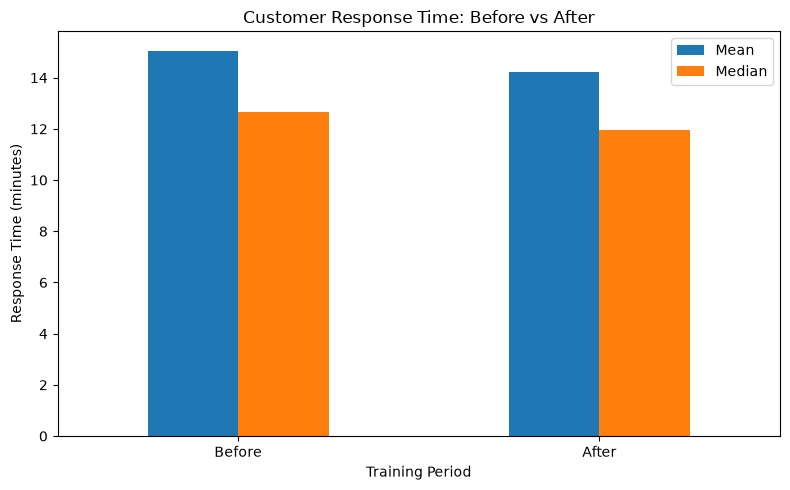

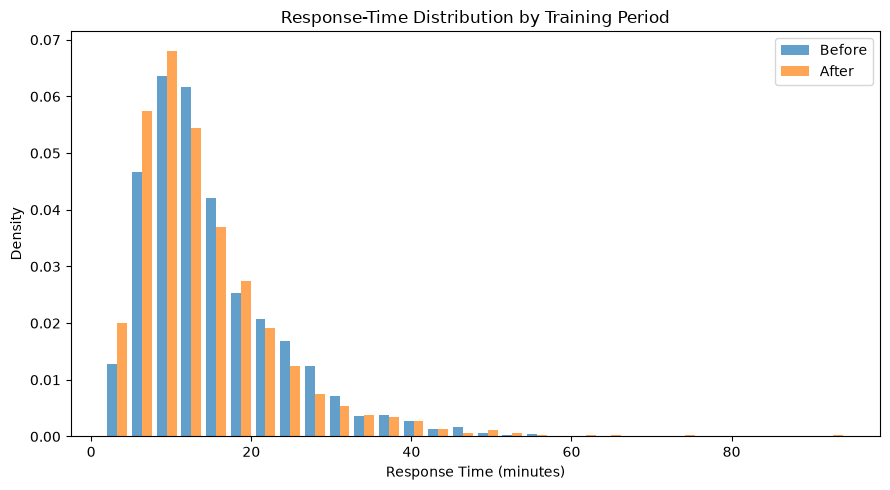

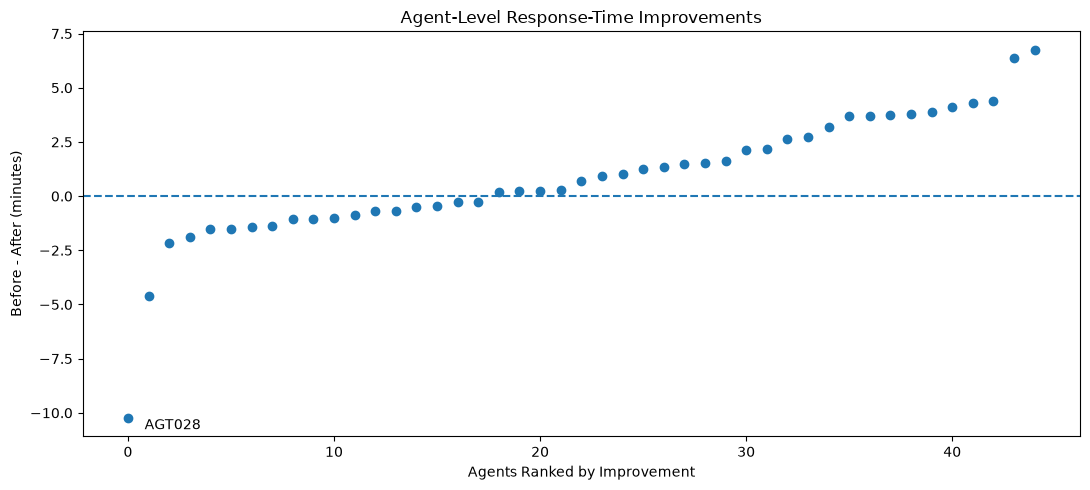

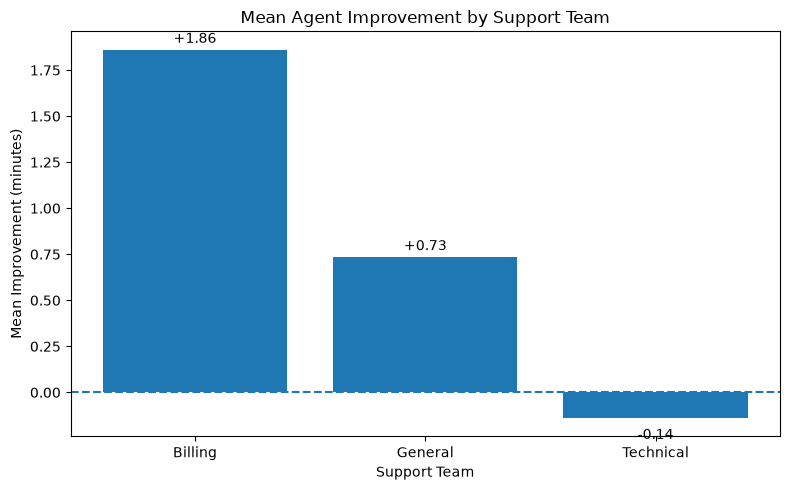

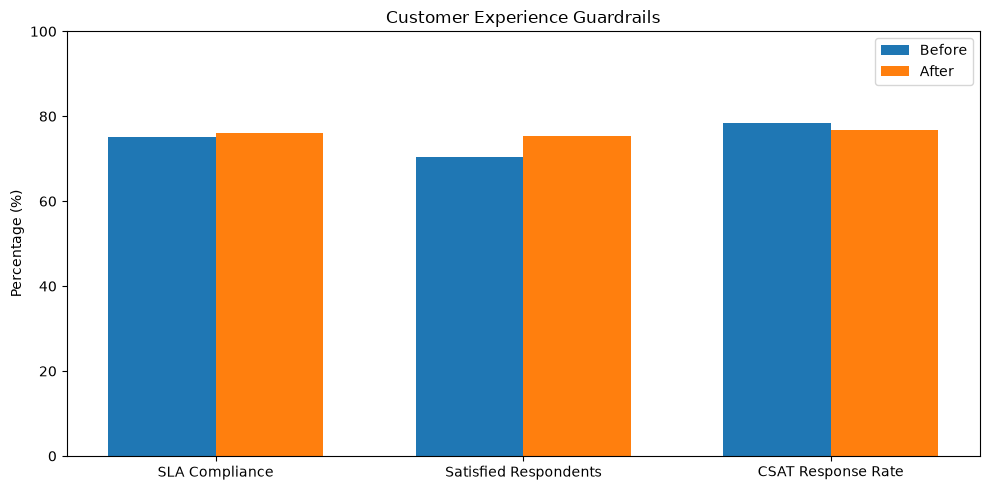

=== SAVED FIGURES ===
01_response_time_comparison.png
02_response_time_distribution.png
03_agent_level_improvements.png
04_team_level_improvements.png
05_customer_experience_guardrails.png

ALL FIVE REQUIRED FIGURES SAVED SUCCESSFULLY
PHASE 3.5 — VISUALIZATION COMPLETE


In [11]:
# ============================================================
# PHASE 3.5 — FINAL FIVE STATISTICAL VISUALIZATIONS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. SET OUTPUT FOLDER
# ------------------------------------------------------------

cwd = Path.cwd()

project_root = next(
    (
        p for p in [cwd, cwd.parent]
        if (p / "data" / "support_tickets.csv").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project data folder."
    )

fig_dir = project_root / "output" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

periods = ["Before", "After"]

# ------------------------------------------------------------
# FIGURE 01 — RESPONSE TIME COMPARISON
# ------------------------------------------------------------

response_summary = (
    clean.groupby("intervention_period")[
        "response_time_minutes"
    ]
    .agg(["mean", "median"])
    .reindex(periods)
)

response_summary.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Customer Response Time: Before vs After")
plt.xlabel("Training Period")
plt.ylabel("Response Time (minutes)")
plt.legend(["Mean", "Median"])
plt.tight_layout()

plt.savefig(
    fig_dir / "01_response_time_comparison.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 02 — RESPONSE TIME DISTRIBUTIONS
# ------------------------------------------------------------

before_times = clean.loc[
    clean["intervention_period"] == "Before",
    "response_time_minutes"
]

after_times = clean.loc[
    clean["intervention_period"] == "After",
    "response_time_minutes"
]

plt.figure(figsize=(9, 5))

plt.hist(
    [before_times, after_times],
    bins=30,
    density=True,
    alpha=0.7,
    label=periods
)

plt.title("Response-Time Distribution by Training Period")
plt.xlabel("Response Time (minutes)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "02_response_time_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 03 — AGENT-LEVEL IMPROVEMENTS
# ------------------------------------------------------------

sorted_agents = (
    agent_pairs.sort_values("improvement_min")
    .reset_index(drop=True)
)

plt.figure(figsize=(11, 5))

plt.scatter(
    np.arange(len(sorted_agents)),
    sorted_agents["improvement_min"]
)

plt.axhline(0, linestyle="--")

outlier_index = sorted_agents.index[
    sorted_agents["agent_id"] == "AGT028"
][0]

plt.annotate(
    "AGT028",
    (
        outlier_index,
        sorted_agents.loc[
            outlier_index,
            "improvement_min"
        ]
    ),
    xytext=(12, -8),
    textcoords="offset points"
)

plt.title("Agent-Level Response-Time Improvements")
plt.xlabel("Agents Ranked by Improvement")
plt.ylabel("Before - After (minutes)")
plt.tight_layout()

plt.savefig(
    fig_dir / "03_agent_level_improvements.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 04 — TEAM-LEVEL IMPROVEMENTS
# ------------------------------------------------------------

team_chart = (
    agent_pairs.groupby("team")["improvement_min"]
    .mean()
    .reindex(["Billing", "General", "Technical"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    team_chart.index,
    team_chart.values
)

plt.axhline(0, linestyle="--")

for bar, value in zip(bars, team_chart.values):
    plt.annotate(
        f"{value:+.2f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 5 if value >= 0 else -15),
        textcoords="offset points",
        ha="center"
    )

plt.title("Mean Agent Improvement by Support Team")
plt.xlabel("Support Team")
plt.ylabel("Mean Improvement (minutes)")
plt.tight_layout()

plt.savefig(
    fig_dir / "04_team_level_improvements.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FIGURE 05 — CUSTOMER EXPERIENCE GUARDRAILS
# ------------------------------------------------------------

metrics = [
    "sla_pct",
    "satisfied_pct",
    "csat_response_pct"
]

metric_labels = [
    "SLA Compliance",
    "Satisfied Respondents",
    "CSAT Response Rate"
]

before_values = guard_overall.loc["Before", metrics]
after_values = guard_overall.loc["After", metrics]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    before_values.astype(float),
    width,
    label="Before"
)

plt.bar(
    x + width / 2,
    after_values.astype(float),
    width,
    label="After"
)

plt.xticks(x, metric_labels)
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)

plt.title("Customer Experience Guardrails")
plt.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "05_customer_experience_guardrails.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

saved_figures = sorted(fig_dir.glob("*.png"))

print("=== SAVED FIGURES ===")

for path in saved_figures:
    print(path.name)

expected_files = [
    "01_response_time_comparison.png",
    "02_response_time_distribution.png",
    "03_agent_level_improvements.png",
    "04_team_level_improvements.png",
    "05_customer_experience_guardrails.png"
]

assert all(
    (fig_dir / filename).is_file()
    for filename in expected_files
)

print("\nALL FIVE REQUIRED FIGURES SAVED SUCCESSFULLY")
print("PHASE 3.5 — VISUALIZATION COMPLETE")

## 8. Decision-focused plots

Phase 3: Create 4–5 clearly titled, correctly labeled plots; save to `output/figures/`.

## 9. Statistical summary and management interpretation

Phase 4: Export accurate statistics to `output/statistical_results.csv`. Develop evidence-backed management recommendations in `docs/executive_decision_report.md`.

## 10. Final reproducibility and QA checklist

Phase 5: Run all cells from a fresh kernel, reconcile calculations, verify assumptions, review conclusions, finalize README and publish a clean GitHub repository.